# Actividad 5. WODPredict-AI: predicción de sobrecarga con MLflow

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/rick-lastra/Actividad_5/blob/main/fuentes/entrena.ipynb)

**Objetivo:** preparar los datos, entrenar modelos y registrar los resultados en MLflow.

**Problema (clasificación):** con la información que se tiene **antes** de entrenar (carga de los últimos días,
frecuencia, ACWR, RPE y comentarios de la sesión anterior), predecir si el atleta tendrá **sobrecarga al día
siguiente** (`overreaching_label` = 1).

**Modelos:** regresión logística, Random Forest y XGBoost, con Grid Search y validación cruzada.


| Sección |   |
|---|---|
| 0 | Preparación del entorno: instala librerias y prepara MLflow |
| A | Descripción del dataset: los carga desde Hugging Face |
| B | Limpieza y estandarización |
| C | Estrategia de versionamiento: muestra la versión V1.0 del dataset |
| D | Visualizaciones gráficas: sobrecarga por nivel, riesgo vs ACWR, outliers, real vs sintético  |
| E | Modelos entrenados: Separa 80/20 por atleta y define regresión logística, Random Forest y XGBoost |
| F | Configuración de hiperparámetros: Grid Search con validación cruzada de 5 folds con registro en MLflow |
| G | Métricas obtenidas: Accuracy, precision, recall, F1 y ROC-AUC en la prueba, matrices de confusión y curva ROC |
| H | Comparación estadística: t pareada y Wilcoxon con 10 folds |
| I | Evidencia de MLflow |
| J | Deuda técnica y MLOps |


## 0. Preparación del entorno

In [1]:
# Sección 0. Preparación del entorno: librerías, carpeta del proyecto y MLflow.

import os
import sys
import subprocess
from pathlib import Path

# En Google Colab se descarga el repositorio y se instalan las librerías que no trae Colab.
EN_COLAB = "google.colab" in sys.modules
if EN_COLAB:
    if not Path("/content/Actividad_5").exists():
        subprocess.run(["git", "clone", "-q", "https://github.com/rick-lastra/Actividad_5.git", "/content/Actividad_5"])
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "mlflow", "xgboost", "huggingface_hub"])
    CARPETA = Path("/content/Actividad_5")
else:
    # En una computadora local el notebook está dentro de la carpeta fuentes/
    CARPETA = Path.cwd().parent if Path.cwd().name == "fuentes" else Path.cwd()

os.chdir(CARPETA)                              # trabajar desde la raíz del repositorio
sys.path.append(str(CARPETA / "fuentes"))      # para poder importar datos_prep.py

import warnings
warnings.filterwarnings("ignore")              # ocultar avisos que no afectan el resultado
os.environ["TQDM_DISABLE"] = "1"               # ocultar barras de progreso de MLflow

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mlflow
import datos_prep as dp                        # nuestras funciones de limpieza

# MLflow guarda todo en el archivo mlflow.db (y los modelos en la carpeta mlruns/).
mlflow.set_tracking_uri("sqlite:///mlflow.db")
mlflow.set_experiment("actividad5-sobrecarga")

# Colores fijos para que cada modelo y cada nivel se vea igual en todas las gráficas.
COLOR = {"Regresión logística": "#2a78d6", "Random Forest": "#eb6834", "XGBoost": "#1baf7a",
         "novato": "#2a78d6", "intermedio": "#eb6834", "élite": "#1baf7a"}
SEMILLA = 42                                   # misma semilla = mismos resultados en cada ejecución

print("Carpeta del proyecto:", CARPETA)
print("MLflow", mlflow.__version__, "| experimento: actividad5-sobrecarga")

2026/10/16 14:51:22 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/16 14:51:22 INFO mlflow.store.db.utils: Updating database tables
2026/10/16 14:51:25 INFO mlflow.tracking.fluent: Experiment with name 'actividad5-sobrecarga' does not exist. Creating a new experiment.


Carpeta del proyecto: /home/rick/Actividad_5
MLflow 3.17.1 | experimento: actividad5-sobrecarga


## A. Descripción del dataset

**Fuente:** dataset público [`rick-lastra/wodpredict-synth`](https://huggingface.co/datasets/rick-lastra/wodpredict-synth)
en Hugging Face, versión `v1.0`. Si no hay internet se usa la copia de `datos/datos_ini/`.

| Archivo | Qué contiene |
|---|---|
| `sessions.csv` | Sintético: una fila por atleta y día entrenado (oct-2024 a sep-2026) |
| `athletes.csv` | Sintético: ficha de los 280 atletas (94 novatos, 93 intermedios, 93 élite) |
| `workouts_sugarwod.csv` | **Real**: exportación de SugarWOD de un atleta (Actividad 4) |

**Supuestos:**
1. Los datos de 280 atletas son sintéticos; la dificultad de cada WOD se tomó de los resultados reales de la Actividad 4.
2. La etiqueta de sobrecarga tiene 5 % de ruido (como pasaría con la evaluación de un coach).
3. `prob_fatiga` es la probabilidad de fatiga que da el modelo de texto de la Actividad 4 a los comentarios.
4. A `sessions.csv` y `athletes.csv` se les agregaron a propósito errores típicos de captura (filas repetidas,
   textos mal escritos, RPE fuera de escala, edades vacías) para practicar la limpieza.

In [2]:
# Sección A. Carga y descripción del dataset.

# 1) Cargar los tres archivos (primero intenta Hugging Face; si falla, usa datos/datos_ini).
sesiones = dp.cargar_csv("sessions.csv")
atletas = dp.cargar_csv("athletes.csv")
sugarwod = dp.cargar_csv("workouts_sugarwod.csv")

# 2) Tamaño de cada tabla.
print("\nsessions.csv:", sesiones.shape[0], "filas x", sesiones.shape[1], "columnas")
print("athletes.csv:", atletas.shape[0], "filas x", atletas.shape[1], "columnas")
print("workouts_sugarwod.csv:", sugarwod.shape[0], "filas x", sugarwod.shape[1], "columnas")

# 3) Diccionario de datos de las columnas que usará el modelo.
diccionario = pd.DataFrame([
    ["level", "categórica", "nivel del atleta: novato / intermedio / élite"],
    ["sex", "categórica", "sexo (F / M)"],
    ["language", "categórica", "idioma de los comentarios (es / en)"],
    ["age", "numérica", "edad en años"],
    ["days_since_prev_session", "numérica", "días desde la sesión anterior"],
    ["sessions_last_3d / 7d / 28d", "numérica", "sesiones en los últimos 3, 7 y 28 días"],
    ["load_last_3d / 7d", "numérica", "carga (RPE x minutos) acumulada en 3 y 7 días"],
    ["mean_session_load_28d", "numérica", "carga promedio por sesión en 28 días"],
    ["acwr_load / acwr3_load", "numérica", "ACWR por carga: carga reciente / carga promedio del mes"],
    ["acwr_freq / acwr3_freq", "numérica", "ACWR por frecuencia: días entrenados recientes / promedio del mes"],
    ["days_since_first_session", "numérica", "antigüedad del atleta en los datos"],
    ["prev_rpe / prev_session_load", "numérica", "RPE (1-10) y carga de la sesión anterior"],
    ["prev_has_note", "numérica", "1 si la sesión anterior tuvo comentario"],
    ["prob_fatiga_prev_session / _last_note", "numérica", "probabilidad de fatiga del comentario anterior / último"],
    ["days_since_last_note / notes_last_28d", "numérica", "días desde el último comentario / comentarios en 28 días"],
    ["overreaching_label", "ETIQUETA", "1 = sobrecarga al día siguiente, 0 = no"],
], columns=["columna", "tipo", "descripción"])
display(diccionario)

# 4) Calidad de los datos originales: tipo, valores vacíos y valores distintos por columna.
calidad = pd.DataFrame({
    "tipo": sesiones.dtypes.astype(str),
    "vacíos": sesiones.isna().sum(),
    "valores distintos": sesiones.nunique(),
})
display(calidad)

sessions.csv: leído de Hugging Face (rick-lastra/wodpredict-synth, versión v1.0)
athletes.csv: leído de Hugging Face (rick-lastra/wodpredict-synth, versión v1.0)
workouts_sugarwod.csv: leído de Hugging Face (rick-lastra/wodpredict-synth, versión v1.0)

sessions.csv: 87258 filas x 39 columnas
athletes.csv: 280 filas x 9 columnas
workouts_sugarwod.csv: 792 filas x 11 columnas


,columna,tipo,descripción
0,level,categórica,nivel del atleta: novato / intermedio / élite
1,sex,categórica,sexo (F / M)
2,language,categórica,idioma de los comentarios (es / en)
3,age,numérica,edad en años
4,days_since_prev_session,numérica,días desde la sesión anterior
5,sessions_last_3d / 7d / 28d,numérica,"sesiones en los últimos 3, 7 y 28 días"
6,load_last_3d / 7d,numérica,carga (RPE x minutos) acumulada en 3 y 7 días
7,mean_session_load_28d,numérica,carga promedio por sesión en 28 días
8,acwr_load / acwr3_load,numérica,ACWR por carga: carga reciente / carga promedi...
9,acwr_freq / acwr3_freq,numérica,ACWR por frecuencia: días entrenados recientes...


,tipo,vacíos,valores distintos
session_id,str,0,85548
athlete_id,str,0,280
date,str,0,626
n_components,int64,0,9
has_metcon,int64,0,2
session_minutes,float64,0,899
rpe,int64,0,10
session_load,float64,0,6393
pr_count,int64,0,3
level,str,0,12


## B. Proceso de limpieza y estandarización

Las reglas están en `fuentes/datos_prep.py` (función `limpiar_sesiones`):

1. **Duplicados exactos:** filas idénticas (la app sincronizó dos veces) → se elimina la copia.
2. **Duplicados por atleta + fecha:** un atleta registra una sola sesión por día; si hay dos, se conserva la más reciente.
3. **Sin etiqueta:** los primeros 28 días de cada atleta no tienen historial suficiente → se eliminan.
4. **Texto:** `level` llega como "Elite", "ÉLITE", "novato " → se unifica en minúsculas; `sex` en mayúsculas.
5. **Reglas de negocio:** RPE debe estar entre 1 y 10, edad entre 16 y 80, ACWR entre 0 y 4 → si no, se deja vacío.
6. **Fuga de información:** se eliminan RPE, carga y comentario **de la misma sesión** (se conocen después de entrenar).

Después, dentro del modelo (para que se ajuste solo con los datos de entrenamiento):
**valores vacíos** → mediana + columna que indica que faltaba; **escalado** → `StandardScaler`;
**categóricas** → `OneHotEncoder` (una columna 0/1 por categoría).

In [3]:
# Sección B. Limpieza y estandarización.

# 1) Limpiar sesiones y atletas con las funciones de datos_prep.py; la bitácora dice qué hizo cada paso.
datos, bitacora = dp.limpiar_sesiones(sesiones, atletas)
display(bitacora)
print(f"Sesiones: {len(sesiones):,} originales -> {len(datos):,} limpias")
print("Valores de level después de limpiar:", datos["level"].value_counts().to_dict())

# 2) Limpiar la exportación real de SugarWOD (fechas, tiempos 'mm:ss' a segundos, score_type vacío).
sugarwod_limpio = dp.limpiar_sugarwod(sugarwod)
print("SugarWOD: WOD con tiempo en segundos:", sugarwod_limpio["tiempo_s"].notna().sum())

# 3) Guardar los datos limpios en datos/datos_limp.
dp.CARPETA_LIMP.mkdir(parents=True, exist_ok=True)
datos.to_csv(dp.CARPETA_LIMP / "sesiones_limpias.csv", index=False)
sugarwod_limpio.to_csv(dp.CARPETA_LIMP / "sugarwod_limpio.csv", index=False)

# 4) Vacíos que quedan: los resuelve el preprocesador del modelo (imputación con la mediana).
vacios = datos.isna().sum()
print("\nVacíos que se imputarán en el modelo:")
print(vacios[vacios > 0])

# 5) Preprocesador: imputación + escalado + one-hot. Se muestra cómo quedan las columnas.
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

def crear_preprocesador(escalar):
    pasos = [("imputar", SimpleImputer(strategy="median", add_indicator=True))]
    if escalar:                                  # solo la regresión logística necesita escalar
        pasos.append(("escalar", StandardScaler()))
    return ColumnTransformer([
        ("num", Pipeline(pasos), dp.NUMERICAS),
        ("cat", OneHotEncoder(handle_unknown="ignore"), dp.CATEGORICAS),
    ])

ejemplo = crear_preprocesador(escalar=True).fit_transform(datos[dp.NUMERICAS + dp.CATEGORICAS])
print(f"\nColumnas de entrada: {len(dp.NUMERICAS + dp.CATEGORICAS)} -> después del preprocesador: {ejemplo.shape[1]}")

,paso,filas o valores afectados
0,Duplicados exactos eliminados,1283
1,Duplicados por atleta + fecha eliminados,427
2,Sesiones sin etiqueta eliminadas,3647
3,Valores de level corregidos,2474
4,Atletas sin edad (se imputa la mediana en el m...,5
5,prev_rpe fuera de rango 1-10 -> vacío,251
6,age fuera de rango 16-80 -> vacío,0
7,acwr_freq fuera de rango 0-4 -> vacío,0
8,acwr_load fuera de rango 0-4 -> vacío,0


Sesiones: 87,258 originales -> 81,901 limpias
Valores de level después de limpiar: {'élite': 34084, 'intermedio': 26672, 'novato': 21145}
SugarWOD: WOD con tiempo en segundos: 142

Vacíos que se imputarán en el modelo:
age                          1456
mean_session_load_28d         148
acwr3_freq                    148
acwr3_load                    148
acwr_freq                     148
acwr_load                     148
prev_rpe                      251
prob_fatiga_prev_session    48805
prob_fatiga_last_note          45
days_since_last_note           45
dtype: int64

Columnas de entrada: 23 -> después del preprocesador: 37


## C. Estrategia de versionamiento

| Qué se versiona | Dónde | Versión |
|---|---|---|
| Datos originales | Hugging Face (`rick-lastra/wodpredict-synth`) | tag `v1.0` |
| Datos originales y limpios, código | GitHub (`rick-lastra/Actividad_5`) | commits y tags `datos-v1.0`, `datos-v1.1`, `v1.0` |
| Historial de cambios | `CHANGELOG.md` | una entrada por versión |
| Experimentos | MLflow | cada run guarda la versión del dataset |

La **huella** (hash) de un archivo cambia si cambia un solo dato: sirve para comprobar que dos entrenamientos usaron
exactamente los mismos datos.

In [4]:
# Sección C. Versionamiento: versión del dataset y huella (hash) de los archivos.
import hashlib

def huella(ruta):
    """Primeros 12 caracteres del hash SHA-256 del archivo."""
    return hashlib.sha256(Path(ruta).read_bytes()).hexdigest()[:12]

print("Dataset en Hugging Face:", dp.HF_DATASET, "| versión:", dp.HF_VERSION)
for ruta in sorted(Path("datos").rglob("*.csv")):
    print(f"{str(ruta):45} huella {huella(ruta)}")

# Historial de versiones (CHANGELOG.md)
print()
print(Path("CHANGELOG.md").read_text(encoding="utf-8"))

Dataset en Hugging Face: rick-lastra/wodpredict-synth | versión: v1.0
datos/datos_ini/athletes.csv                  huella 055bee115102
datos/datos_ini/sessions.csv                  huella a2d5445127cd
datos/datos_ini/workouts_sugarwod.csv         huella 6616a54f7c2d
datos/datos_limp/sesiones_limpias.csv         huella 4256b41dc567
datos/datos_limp/sugarwod_limpio.csv          huella b29b402ce8fc

# CHANGELOG

Historial de versiones del proyecto. Los datos y el código se marcan con tags de Git.

## v1.0 (2026-10-16) - Reporte final

- `fuentes/entrena.ipynb`: notebook con una sección por punto del reporte técnico (A a J).
- `fuentes/train.py`: entrenamiento de 3 modelos con Grid Search y registro en MLflow.
- Resultados en el 20 % de prueba (atletas nuevos), por ROC-AUC: regresión logística 0.859, XGBoost 0.855,
  Random Forest 0.854. La t pareada y Wilcoxon (10 folds) no encuentran diferencias significativas, así que se
  elige el modelo más simple: regresión logística.

## datos-v1.1

## D. Visualizaciones: patrones y anomalías

1. **Desbalance:** ¿cuántas sesiones terminan en sobrecarga y cómo cambia por nivel?
2. **Patrón principal:** ¿cómo sube el riesgo con el ACWR por carga?
3. **Anomalías:** cargas fuera de lo normal (outliers por el método IQR).
4. **Realismo:** sesiones por semana del atleta real frente a los atletas sintéticos.

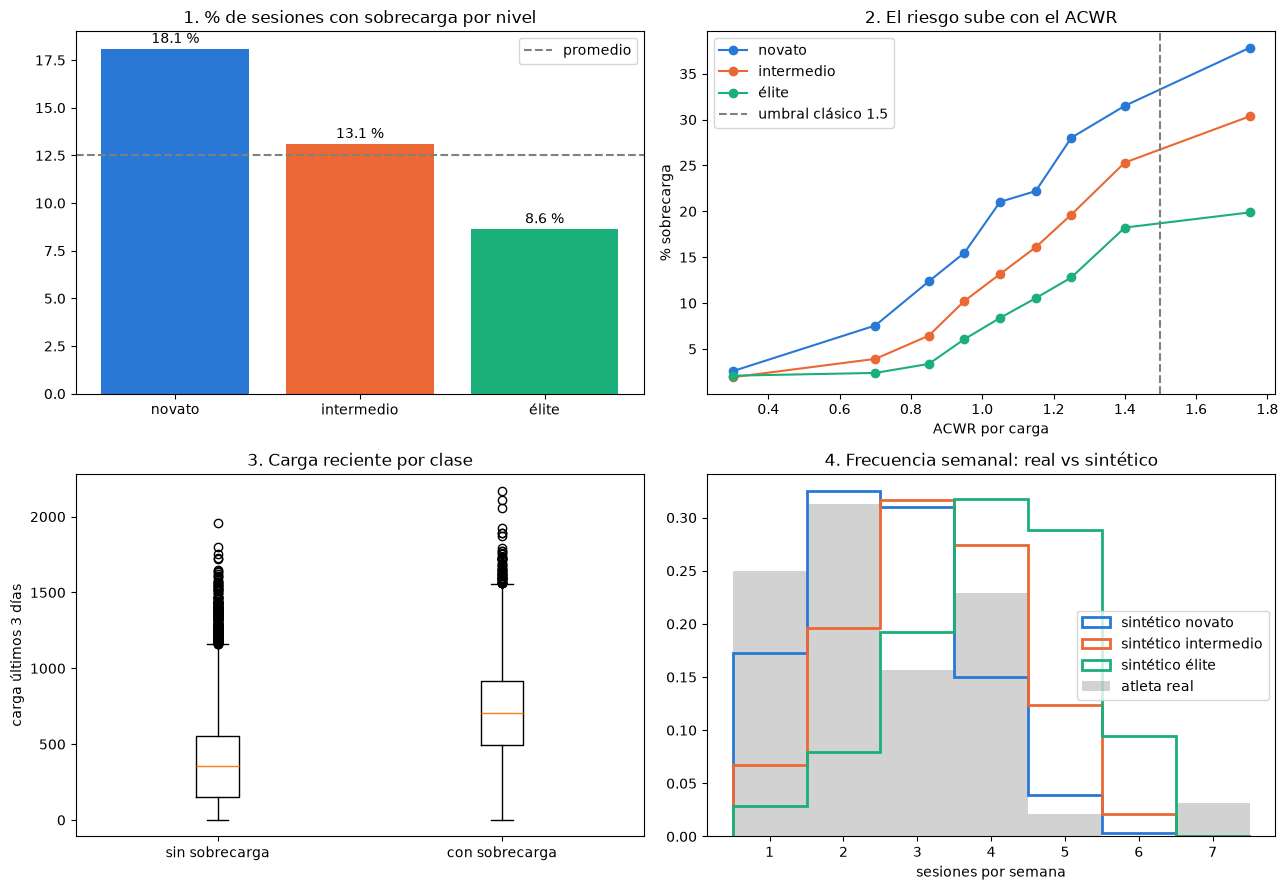

Variables más relacionadas con la sobrecarga:
load_last_3d         0.328
acwr3_load           0.295
load_last_7d         0.294
acwr_load            0.264
prev_session_load    0.237
dtype: float64

Outliers por IQR (se conservan: son cargas altas reales, no errores):
  load_last_3d: 543 outliers (0.7%); 70% de ellos con sobrecarga
  load_last_7d: 408 outliers (0.5%); 58% de ellos con sobrecarga
  acwr_load: 2,639 outliers (3.2%); 23% de ellos con sobrecarga


In [5]:
# Sección D. Visualizaciones para detectar patrones y anomalías.

niveles = ["novato", "intermedio", "élite"]
fig, ejes = plt.subplots(2, 2, figsize=(13, 9))

# 1) % de sesiones con sobrecarga por nivel (desbalance de clases).
porcentaje = datos.groupby("level")["overreaching_label"].mean().reindex(niveles) * 100
ejes[0, 0].bar(niveles, porcentaje, color=[COLOR[n] for n in niveles])
for i, valor in enumerate(porcentaje):
    ejes[0, 0].text(i, valor + 0.3, f"{valor:.1f} %", ha="center")
ejes[0, 0].axhline(datos["overreaching_label"].mean() * 100, color="gray", linestyle="--", label="promedio")
ejes[0, 0].set_title("1. % de sesiones con sobrecarga por nivel")
ejes[0, 0].legend()

# 2) Riesgo de sobrecarga según el ACWR por carga (agrupado en intervalos).
cortes = [0, 0.6, 0.8, 0.9, 1.0, 1.1, 1.2, 1.3, 1.5, 4]
datos["acwr_intervalo"] = pd.cut(datos["acwr_load"], cortes)
for nivel in niveles:
    del_nivel = datos[datos["level"] == nivel]
    riesgo = del_nivel.groupby("acwr_intervalo", observed=False)["overreaching_label"].mean() * 100
    centros = [(i.left + min(i.right, 2)) / 2 for i in riesgo.index]
    ejes[0, 1].plot(centros, riesgo.values, marker="o", color=COLOR[nivel], label=nivel)
ejes[0, 1].axvline(1.5, color="gray", linestyle="--", label="umbral clásico 1.5")
ejes[0, 1].set_xlabel("ACWR por carga")
ejes[0, 1].set_ylabel("% sobrecarga")
ejes[0, 1].set_title("2. El riesgo sube con el ACWR")
ejes[0, 1].legend()
datos = datos.drop(columns="acwr_intervalo")

# 3) Carga de los últimos 3 días según la clase (los puntos son outliers).
sin = datos.loc[datos["overreaching_label"] == 0, "load_last_3d"]
con = datos.loc[datos["overreaching_label"] == 1, "load_last_3d"]
ejes[1, 0].boxplot([sin, con], tick_labels=["sin sobrecarga", "con sobrecarga"])
ejes[1, 0].set_ylabel("carga últimos 3 días")
ejes[1, 0].set_title("3. Carga reciente por clase")

# 4) Sesiones por semana: atleta real (SugarWOD) vs atletas sintéticos.
real = sugarwod_limpio.drop_duplicates("date").set_index("date").resample("W").size()
real = real[real > 0]
semanas = datos.groupby(["athlete_id", "level", datos["date"].dt.to_period("W")]).size().reset_index(name="n")
for nivel in niveles:
    ejes[1, 1].hist(semanas.loc[semanas["level"] == nivel, "n"], bins=np.arange(0.5, 7.6, 1),
                    density=True, histtype="step", linewidth=2, color=COLOR[nivel], label=f"sintético {nivel}")
ejes[1, 1].hist(real, bins=np.arange(0.5, 7.6, 1), density=True, color="gray", alpha=0.35, label="atleta real")
ejes[1, 1].set_xlabel("sesiones por semana")
ejes[1, 1].set_title("4. Frecuencia semanal: real vs sintético")
ejes[1, 1].legend()

plt.tight_layout()
plt.show()

# Variables más relacionadas con la etiqueta (correlación de Spearman).
correlacion = datos[dp.NUMERICAS].corrwith(datos["overreaching_label"], method="spearman")
print("Variables más relacionadas con la sobrecarga:")
print(correlacion.abs().sort_values(ascending=False).head(5).round(3))

# Outliers por IQR: valores más allá de 1.5 veces el rango intercuartil.
print("\nOutliers por IQR (se conservan: son cargas altas reales, no errores):")
for columna in ["load_last_3d", "load_last_7d", "acwr_load"]:
    q1, q3 = datos[columna].quantile([0.25, 0.75])
    limite = q3 + 1.5 * (q3 - q1)
    outliers = datos[datos[columna] > limite]
    print(f"  {columna}: {len(outliers):,} outliers ({len(outliers) / len(datos):.1%}); "
          f"{outliers['overreaching_label'].mean():.0%} de ellos con sobrecarga")

## E. Modelos entrenados

| Modelo | Cómo funciona | Por qué se eligió |
|---|---|---|
| **Regresión logística** | Suma ponderada de las variables convertida en probabilidad | Línea base simple e interpretable |
| **Random Forest** | Muchos árboles de decisión que votan | Capta relaciones no lineales (el riesgo se dispara con el ACWR) |
| **XGBoost** | Árboles que se construyen uno tras otro corrigiendo errores | Suele ser el más fuerte en datos de tabla |

**Separación de datos:** 80 % para entrenar y 20 % para probar, **por atleta**: los atletas de prueba nunca se vieron
en el entrenamiento (como un atleta nuevo que llega al box).

In [6]:
# Sección E. Separación de datos y definición de los tres modelos.
from sklearn.model_selection import GroupShuffleSplit
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# 1) Variables de entrada (X), etiqueta (y) y atleta de cada sesión (grupo).
X = datos[dp.NUMERICAS + dp.CATEGORICAS]
y = datos["overreaching_label"]
atleta = datos["athlete_id"]

# 2) Separación 80/20 por atleta.
separador = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEMILLA)
idx_train, idx_test = next(separador.split(X, y, groups=atleta))
X_train, X_test = X.iloc[idx_train], X.iloc[idx_test]
y_train, y_test = y.iloc[idx_train], y.iloc[idx_test]
atleta_train = atleta.iloc[idx_train]
print(f"Entrenamiento: {len(X_train):,} sesiones de {atleta_train.nunique()} atletas ({y_train.mean():.1%} con sobrecarga)")
print(f"Prueba:        {len(X_test):,} sesiones de {atleta.iloc[idx_test].nunique()} atletas ({y_test.mean():.1%} con sobrecarga)")

# 3) Cada modelo es un Pipeline: preprocesador (sección B) + clasificador.
modelos = {
    "Regresión logística": Pipeline([
        ("prep", crear_preprocesador(escalar=True)),
        ("modelo", LogisticRegression(max_iter=3000, random_state=SEMILLA))]),
    "Random Forest": Pipeline([
        ("prep", crear_preprocesador(escalar=False)),
        ("modelo", RandomForestClassifier(n_estimators=200, class_weight="balanced_subsample",
                                          n_jobs=-1, random_state=SEMILLA))]),
    "XGBoost": Pipeline([
        ("prep", crear_preprocesador(escalar=False)),
        ("modelo", XGBClassifier(n_estimators=300, subsample=0.8, colsample_bytree=0.8,
                                 eval_metric="logloss", n_jobs=-1, random_state=SEMILLA))]),
}
for nombre in modelos:
    print("-", nombre, "->", type(modelos[nombre].named_steps["modelo"]).__name__)

Entrenamiento: 65,403 sesiones de 224 atletas (12.5% con sobrecarga)
Prueba:        16,498 sesiones de 56 atletas (12.6% con sobrecarga)
- Regresión logística -> LogisticRegression
- Random Forest -> RandomForestClassifier
- XGBoost -> XGBClassifier


## F. Configuración de hiperparámetros (Grid Search + validación cruzada)

`GridSearchCV` prueba todas las combinaciones de la rejilla con **validación cruzada de 5 folds por atleta**
(`GroupKFold`) y se queda con la de mayor **ROC-AUC**. Se usa ROC-AUC porque solo 12.5 % de las sesiones son
positivas: un modelo que siempre dijera "no" tendría 87.5 % de accuracy sin servir para nada.

| Modelo | Hiperparámetro | Valores | Justificación |
|---|---|---|---|
| Regresión logística | `C` | 0.01, 0.1, 1, 10 | fuerza de la regularización (menor C = modelo más simple) |
| | `class_weight` | None, balanced | compensar que hay pocos casos de sobrecarga |
| Random Forest | `max_depth` | 8, 16 | profundidad de cada árbol: controla el sobreajuste |
| | `min_samples_leaf` | 5, 25 | mínimo de sesiones por hoja: suaviza las predicciones |
| | `max_features` | sqrt, 0.5 | cuántas variables mira cada árbol: árboles más diversos |
| XGBoost | `max_depth` | 3, 5 | árboles poco profundos combinan pocas variables a la vez |
| | `learning_rate` | 0.05, 0.1 | tamaño de cada corrección: más pequeño generaliza mejor |
| | `scale_pos_weight` | 1, negativos/positivos | equivalente a `class_weight` para XGBoost |

Cada modelo se registra en MLflow como un *run*, y cada combinación probada como un *run hijo*.

In [7]:
# Sección F. Grid Search con validación cruzada y registro en MLflow (tarda unos minutos).
from sklearn.model_selection import GridSearchCV, GroupKFold
from mlflow.models import infer_signature

# 1) Rejillas de hiperparámetros ("modelo__" indica que el parámetro es del clasificador del Pipeline).
proporcion = round((y_train == 0).sum() / (y_train == 1).sum(), 2)    # negativos / positivos
rejillas = {
    "Regresión logística": {"modelo__C": [0.01, 0.1, 1, 10],
                            "modelo__class_weight": [None, "balanced"]},
    "Random Forest": {"modelo__max_depth": [8, 16],
                      "modelo__min_samples_leaf": [5, 25],
                      "modelo__max_features": ["sqrt", 0.5]},
    "XGBoost": {"modelo__max_depth": [3, 5],
                "modelo__learning_rate": [0.05, 0.1],
                "modelo__scale_pos_weight": [1, proporcion]},
}

# 2) Entrenar cada modelo y registrar en MLflow.
busquedas = {}      # aquí se guarda el GridSearchCV ya entrenado de cada modelo
run_ids = {}        # id del run de MLflow de cada modelo (se usa en la sección G)
for nombre in modelos:
    print("Entrenando", nombre, "...")
    busqueda = GridSearchCV(modelos[nombre], rejillas[nombre], cv=GroupKFold(n_splits=5), scoring="roc_auc")

    with mlflow.start_run(run_name=nombre) as run:
        busqueda.fit(X_train, y_train, groups=atleta_train)

        # Un run hijo por cada combinación probada, con su ROC-AUC promedio en validación.
        resultados = pd.DataFrame(busqueda.cv_results_)
        for i in range(len(resultados)):
            with mlflow.start_run(run_name=f"{nombre} - combinación {i + 1}", nested=True):
                mlflow.log_params(resultados.loc[i, "params"])
                mlflow.log_metric("cv_roc_auc", resultados.loc[i, "mean_test_score"])

        # En el run del modelo: mejores hiperparámetros, ROC-AUC de validación, versión de datos y el modelo.
        mlflow.log_params(busqueda.best_params_)
        mlflow.log_param("dataset", f"{dp.HF_DATASET}@{dp.HF_VERSION}")
        mlflow.log_param("validacion", "GroupKFold(5) por atleta")
        mlflow.log_metric("cv_roc_auc", busqueda.best_score_)
        mlflow.sklearn.log_model(busqueda.best_estimator_, name="modelo", serialization_format="cloudpickle",
                                 signature=infer_signature(X_test, busqueda.predict_proba(X_test)[:, 1]))

    busquedas[nombre] = busqueda
    run_ids[nombre] = run.info.run_id

    # Mostrar las 3 mejores combinaciones de este modelo.
    tabla = resultados[["params", "mean_test_score", "std_test_score", "rank_test_score"]]
    tabla = tabla.sort_values("rank_test_score").head(3)
    tabla.columns = ["hiperparámetros", "ROC-AUC promedio", "desviación", "lugar"]
    display(tabla.round(4))

Entrenando Regresión logística ...


2026/10/16 14:52:38 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


,hiperparámetros,ROC-AUC promedio,desviación,lugar
2,"{'modelo__C': 0.1, 'modelo__class_weight': None}",0.8521,0.0038,1
4,"{'modelo__C': 1, 'modelo__class_weight': None}",0.8520,0.0039,2
6,"{'modelo__C': 10, 'modelo__class_weight': None}",0.8520,0.0039,3


Entrenando Random Forest ...


2026/10/16 14:56:55 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


,hiperparámetros,ROC-AUC promedio,desviación,lugar
5,"{'modelo__max_depth': 16, 'modelo__max_feature...",0.8514,0.0041,1
1,"{'modelo__max_depth': 8, 'modelo__max_features...",0.8507,0.0032,2
0,"{'modelo__max_depth': 8, 'modelo__max_features...",0.8503,0.0034,3


Entrenando XGBoost ...


2026/10/16 14:58:01 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


,hiperparámetros,ROC-AUC promedio,desviación,lugar
0,"{'modelo__learning_rate': 0.05, 'modelo__max_d...",0.8503,0.0051,1
1,"{'modelo__learning_rate': 0.05, 'modelo__max_d...",0.8501,0.0042,2
4,"{'modelo__learning_rate': 0.1, 'modelo__max_de...",0.8476,0.0054,3


## G. Métricas obtenidas

Se evalúa el mejor modelo de cada tipo en el 20 % de prueba (atletas nuevos). Se predice "sobrecarga" cuando la
probabilidad es mayor o igual a 0.5.

- **Accuracy:** % de aciertos totales.
- **Precision:** de las alertas que da el modelo, cuántas eran sobrecarga real.
- **Recall:** de las sobrecargas reales, cuántas detectó.
- **F1:** equilibrio entre precision y recall.
- **ROC-AUC:** qué tan bien separa los dos grupos sin importar el umbral (0.5 = azar, 1 = perfecto).

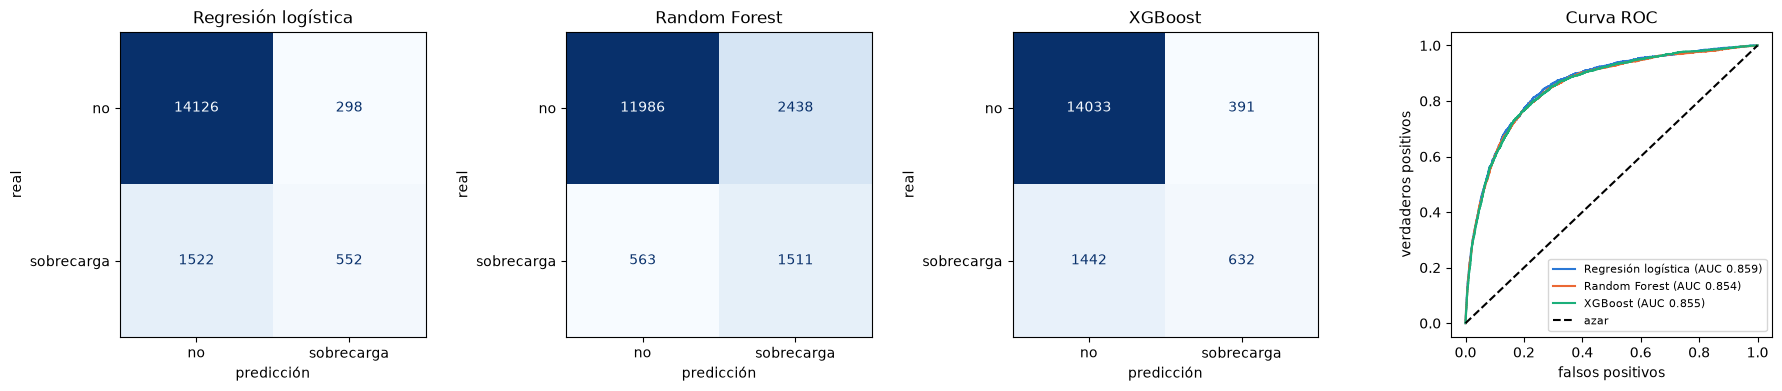

,accuracy,precision,recall,f1,roc_auc
modelo,,,,,
Regresión logística,0.890,0.649,0.266,0.378,0.859
Random Forest,0.818,0.383,0.729,0.502,0.854
XGBoost,0.889,0.618,0.305,0.408,0.855


In [8]:
# Sección G. Métricas en el conjunto de prueba, matrices de confusión y curva ROC.
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             roc_curve, ConfusionMatrixDisplay)

filas = []
probabilidades = {}
fig, ejes = plt.subplots(1, 4, figsize=(18, 4))
for i, nombre in enumerate(busquedas):
    # 1) Probabilidad de sobrecarga y predicción (1 si la probabilidad >= 0.5).
    prob = busquedas[nombre].predict_proba(X_test)[:, 1]
    pred = (prob >= 0.5).astype(int)
    probabilidades[nombre] = prob

    # 2) Las cinco métricas de clasificación.
    m = {"accuracy": accuracy_score(y_test, pred), "precision": precision_score(y_test, pred),
         "recall": recall_score(y_test, pred), "f1": f1_score(y_test, pred),
         "roc_auc": roc_auc_score(y_test, prob)}
    filas.append({"modelo": nombre, **m})

    # 3) Guardar las métricas de prueba en el run de MLflow de ese modelo.
    with mlflow.start_run(run_id=run_ids[nombre]):
        for metrica, valor in m.items():
            mlflow.log_metric("test_" + metrica, valor)

    # 4) Matriz de confusión.
    ConfusionMatrixDisplay.from_predictions(y_test, pred, ax=ejes[i], colorbar=False, cmap="Blues",
                                            display_labels=["no", "sobrecarga"])
    ejes[i].set_title(nombre)
    ejes[i].set_xlabel("predicción")
    ejes[i].set_ylabel("real")

    # 5) Curva ROC.
    fpr, tpr, _ = roc_curve(y_test, prob)
    ejes[3].plot(fpr, tpr, color=COLOR[nombre], label=f"{nombre} (AUC {m['roc_auc']:.3f})")

ejes[3].plot([0, 1], [0, 1], "k--", label="azar")
ejes[3].set_xlabel("falsos positivos")
ejes[3].set_ylabel("verdaderos positivos")
ejes[3].set_title("Curva ROC")
ejes[3].legend(fontsize=8)
plt.tight_layout()
plt.show()

metricas = pd.DataFrame(filas).set_index("modelo").round(3)
display(metricas)

## H. Comparación estadística de resultados

¿Las diferencias entre modelos son reales o casualidad? Los tres modelos se evalúan en los **mismos 10 folds por
atleta** y se comparan fold por fold con las dos pruebas del tema 12:

- **t de Student pareada** (supone que las diferencias son normales).
- **Wilcoxon** (no supone normalidad).

Si p < 0.05 la diferencia es significativa. Como se hacen 3 comparaciones, se usa el criterio más estricto de
Bonferroni: p < 0.05 / 3 = 0.0167.

Regresión logística: ROC-AUC = 0.8520 ± 0.0101
Random Forest: ROC-AUC = 0.8517 ± 0.0089
XGBoost: ROC-AUC = 0.8512 ± 0.0096


,comparación,diferencia de ROC-AUC,p t pareada,p Wilcoxon,¿significativa?
0,Regresión logística vs Random Forest,0.0003,0.7498,0.4316,no
1,Regresión logística vs XGBoost,0.0008,0.6984,0.6953,no
2,Random Forest vs XGBoost,0.0005,0.7991,0.9219,no


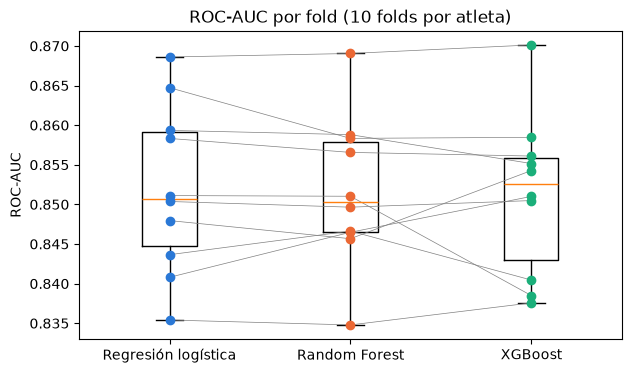

In [9]:
# Sección H. Comparación estadística con t pareada y Wilcoxon (10 folds por atleta).
from sklearn.model_selection import cross_val_score
from scipy import stats

# 1) ROC-AUC de cada modelo en los mismos 10 folds.
puntajes = {}
for nombre in busquedas:
    puntajes[nombre] = cross_val_score(busquedas[nombre].best_estimator_, X_train, y_train,
                                       groups=atleta_train, cv=GroupKFold(n_splits=10), scoring="roc_auc")
    print(f"{nombre}: ROC-AUC = {puntajes[nombre].mean():.4f} ± {puntajes[nombre].std():.4f}")

# 2) Pruebas por pares.
nombres = list(puntajes)
filas = []
with mlflow.start_run(run_name="comparación estadística"):
    for i in range(len(nombres)):
        for j in range(i + 1, len(nombres)):
            a, b = nombres[i], nombres[j]
            p_t = stats.ttest_rel(puntajes[a], puntajes[b]).pvalue
            p_w = stats.wilcoxon(puntajes[a], puntajes[b]).pvalue
            filas.append({"comparación": f"{a} vs {b}",
                          "diferencia de ROC-AUC": puntajes[a].mean() - puntajes[b].mean(),
                          "p t pareada": p_t, "p Wilcoxon": p_w,
                          "¿significativa?": "sí" if (p_t < 0.05 / 3 and p_w < 0.05 / 3) else "no"})
            mlflow.log_metric(f"p_t {a} vs {b}", p_t)
            mlflow.log_metric(f"p_wilcoxon {a} vs {b}", p_w)
display(pd.DataFrame(filas).round(4))

# 3) Gráfica: cada punto es un fold; las líneas grises unen el mismo fold en los tres modelos.
plt.figure(figsize=(7, 4))
plt.boxplot([puntajes[n] for n in nombres], tick_labels=nombres)
for k in range(10):
    plt.plot([1, 2, 3], [puntajes[n][k] for n in nombres], color="gray", linewidth=0.5)
for i, n in enumerate(nombres):
    plt.scatter([i + 1] * 10, puntajes[n], color=COLOR[n], zorder=3)
plt.ylabel("ROC-AUC")
plt.title("ROC-AUC por fold (10 folds por atleta)")
plt.show()

## I. Evidencia del uso de MLflow

La tabla sale directamente de MLflow. Para ver el panel en el navegador, en una terminal dentro de la carpeta del
repositorio:

```bash
mlflow ui --backend-store-uri sqlite:///mlflow.db --port 5000
```

y abrir http://127.0.0.1:5000.  

In [13]:
# Sección I. Lo que quedó registrado en MLflow.

# 1) Todos los runs del experimento.
runs = mlflow.search_runs(experiment_names=["actividad5-sobrecarga"])
hijos = runs["tags.mlflow.parentRunId"].notna()
print(f"Runs registrados: {len(runs)} ({hijos.sum()} combinaciones del grid + {(~hijos).sum()} runs principales)")

# 2) Runs principales con sus métricas.
columnas = ["tags.mlflow.runName", "params.dataset", "metrics.cv_roc_auc", "metrics.test_accuracy",
            "metrics.test_precision", "metrics.test_recall", "metrics.test_f1", "metrics.test_roc_auc"]
principales = runs.loc[~hijos & runs["params.dataset"].notna(), columnas]
display(principales.round(3))

# 3) El modelo quedó guardado: se carga desde MLflow y se usa para predecir 5 sesiones de prueba.
mejor = metricas["roc_auc"].idxmax()
modelo_guardado = mlflow.sklearn.load_model(f"runs:/{run_ids[mejor]}/modelo")
print("Mejor modelo por ROC-AUC:", mejor)
print("Probabilidad de sobrecarga de 5 sesiones:", modelo_guardado.predict_proba(X_test.head())[:, 1].round(3))

Runs registrados: 28 (24 combinaciones del grid + 4 runs principales)


,tags.mlflow.runName,params.dataset,metrics.cv_roc_auc,metrics.test_accuracy,metrics.test_precision,metrics.test_recall,metrics.test_f1,metrics.test_roc_auc
9,XGBoost,rick-lastra/wodpredict-synth@v1.0,0.850,0.889,0.618,0.305,0.408,0.855
18,Random Forest,rick-lastra/wodpredict-synth@v1.0,0.851,0.818,0.383,0.729,0.502,0.854
27,Regresión logística,rick-lastra/wodpredict-synth@v1.0,0.852,0.890,0.649,0.266,0.378,0.859


Mejor modelo por ROC-AUC: Regresión logística
Probabilidad de sobrecarga de 5 sesiones: [0.357 0.606 0.005 0.029 0.005]


## J. Reflexión sobre deuda técnica y MLOps

> **Rick:** escribe aquí la reflexión con tus palabras. La celda de abajo da datos de apoyo.

Ideas para desarrollar:
- **Deuda de datos:** datos sintéticos; el único dato real es de un atleta.
- **Deuda de configuración:** las rejillas y semillas están escritas en el código.
- **Desbalance y umbral:** las métricas dependen del umbral 0.5.
- **Equidad:** la sobrecarga es más frecuente en novatos que en élite.
- **MLOps:** automatizar limpieza y entrenamiento, servidor de MLflow compartido, monitorear los datos nuevos,
  reentrenar con datos reales.

In [11]:
# Sección J. Datos de apoyo para la reflexión: desempeño del mejor modelo por nivel del atleta.
pred_mejor = (probabilidades[mejor] >= 0.5).astype(int)
prueba = X_test.copy()
prueba["real"] = y_test.values
prueba["prediccion"] = pred_mejor
prueba["probabilidad"] = probabilidades[mejor]

filas = []
for nivel in ["novato", "intermedio", "élite"]:
    p = prueba[prueba["level"] == nivel]
    filas.append({"nivel": nivel, "sesiones": len(p), "% con sobrecarga": p["real"].mean() * 100,
                  "recall": recall_score(p["real"], p["prediccion"]),
                  "f1": f1_score(p["real"], p["prediccion"]),
                  "roc_auc": roc_auc_score(p["real"], p["probabilidad"])})
print("Mejor modelo:", mejor)
display(pd.DataFrame(filas).set_index("nivel").round(3))

Mejor modelo: Regresión logística


,sesiones,% con sobrecarga,recall,f1,roc_auc
nivel,,,,,
novato,4946,18.378,0.341,0.457,0.862
intermedio,4541,13.213,0.258,0.370,0.858
élite,7011,8.059,0.154,0.239,0.833
